---
title: "Chapter 18: Natural Language Processing"
---

::: {.callout-lo}

## Learning outcomes {.unnumbered}

By the end of this chapter, you should be able to:

- Explain why ambiguity, context, and vocabulary mismatch make language difficult to represent computationally.
- Interpret bag-of-words, TF–IDF, and sentence-embedding examples, and explain what information these representations preserve or miss.
- Interpret similarity and analogy results from pretrained word embeddings, and explain how learned associations can reflect social biases.
- Compare sparse and dense retrieval, explain the role of cosine similarity, and assess whether ranked results are useful for a query.
- Explain next-token prediction intuitively and distinguish pretraining, post-training, and prompting.
- Distinguish giving a model clearer instructions from supplying new evidence, and explain how retrieval-augmented generation (RAG) uses that evidence.
- Explain the main stages of a RAG pipeline and use retrieved passages, prompts, and generated answers to identify where a system may have gone wrong.

:::

**Imports**

In [ ]:
#| code-fold: true
#| code-summary: "Show imports and setup"

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", 120)

## What is natural language processing?

Before arriving at this page today, you may already have interacted with several systems that process language. Perhaps your phone completed a sentence, an email service filtered spam, a search engine interpreted a query, or a chatbot answered a question. These tools feel quite different, but they all face the same basic challenge: **how can a computer do something useful with human language?**

:::: {.columns}

::: {.column width="50%"}
![](img/gmail-spam-example.png){fig-alt="An email interface marking a message as spam"}

A spam filter classifies incoming messages.
:::

::: {.column width="50%"}
![](img/voice-assistant-ex.png){fig-alt="A language model assigns a higher probability to I have read this book than to the similar-sounding eye have red this book"}

A language model helps a speech recognizer choose the more plausible sequence of words.
:::

::::

**Natural language processing (NLP)** is the area of artificial intelligence concerned with analyzing and generating human language. NLP applications include search, translation, sentiment analysis, document classification, summarization, speech recognition, information extraction, and conversational assistants.

![](img/WhatisNLP.png){fig-align="center" width="600" fig-alt="Examples of natural language processing tasks"}

Natural language processing is a broad field, and this chapter offers a first look at a few ideas behind modern language applications. We begin with how computers represent text numerically, building on the bag-of-words features and sentence embeddings you have already used. We then explore how these representations help us retrieve relevant information and how large language models generate text. Finally, we bring retrieval and generation together in **retrieval-augmented generation (RAG)**: finding relevant source material and supplying it to a language model to help answer a question.

Our goal is to build intuition about how these systems work. The code examples make the steps visible; you are not expected to reproduce the implementation or memorize library calls. Focus on what each component receives, what it produces, and how to interpret the results. By the end, you should be able to explain how a RAG system answers a question and assess whether its answer is supported by the retrieved evidence.

At first, this might sound like a matter of programming enough vocabulary and grammar rules. Language, however, rarely follows a tidy collection of rules.

### Why is language difficult?

Consider the following sentence. To what does *it* refer?

![](img/referential_ambiguity.png){fig-align="center" width="750" fig-alt="A conversation illustrating that a pronoun can have an ambiguous referent"}

A human reader looks beyond the pronoun. We use the surrounding conversation, common sense, and knowledge of the world. Even then, we sometimes need to ask for clarification.

Ambiguity is not limited to pronouns. Consider these genuine-style [ambiguous newspaper headlines](https://www.ling.upenn.edu/~beatrice/humor/headlines.html):

> KICKING BABY CONSIDERED TO BE HEALTHY

> MILK DRINKERS ARE TURNING TO POWDER

Why are they funny? In the first headline, *kicking* can describe the baby or an action performed on the baby. In the second, *turning to* can mean *choosing* or *transforming into*. The intended meanings are ordinary; the unintended interpretations are surprising.

The words themselves have not changed. What changes is how we connect them.

### Context changes meaning

What would you put in each blank?

> I went to the bank to deposit some ________.

> I sat on the bank of the ________.

The nearby words make *bank* mean different things. Language also permits the reverse problem: two sentences can express similar ideas with few words in common. *The assignment deadline passed while I was ill* and *I was sick when my homework was due* are likely asking about the same policy. A useful NLP system needs to handle both exact wording and paraphrases.

This observation will matter throughout the chapter. Search based only on matching words may miss a relevant passage, while a model that focuses only on broad similarity may overlook an important exact term.

### From language to numbers

Machine learning models operate on numbers, not directly on words. Before a model can classify, retrieve, or generate text, the system must decide how to represent language numerically. That representation determines which similarities and differences the model can notice.

No representation captures every aspect of meaning. The right question is therefore not ''Does the computer truly understand this sentence?'' but ''Does this representation retain the information needed for our task?'' We begin with representations based on word counts and then move to embeddings designed to capture some aspects of meaning.

## Representing text

### Sparse representations: bag-of-words and TF–IDF

In Chapter 6, we used **bag-of-words** features to represent a document by the words it contains. There is one feature for each term in the vocabulary, and the feature value records how often that term occurs. Because a document contains only a small fraction of the full vocabulary, most values are zero. Bag-of-words is therefore called a **sparse representation**.

We will explore sparse and dense representations using a small campus-survival store. It gives us queries that depend on ordinary meaning, such as *I want to study without hearing the conversation at the next table*, as well as queries containing exact specifications or model numbers, such as *20,000 mAh* and *HUB-7X*.

#### A campus-survival catalog

Each row below is a document that a shopping search system might return. Most rows describe products that could be useful to university students. The collection also contains two informational articles. These distractors will help us see the difference between matching related words and identifying what a shopper probably wants.

The Sony headphones are included as a familiar example, not as a product endorsement. The noise-cancellation and battery-life details come from the [manufacturer's specifications](https://www.sony.com/electronics/support/wireless-headphones-bluetooth-headphones/wh-1000xm6/specifications).

In [2]:
products = pd.DataFrame(
    [
        ("C001", "Sony WH-1000XM6 headphones", "Over-ear wireless headphones with active noise cancellation and up to 30 hours of battery life. Useful for studying in noisy spaces."),
        ("C002", "Pocket power bank", "Portable 20,000 mAh battery with two USB-C ports. Recharges mobile devices several times when wall power is unavailable."),
        ("C003", "Waterproof laptop backpack", "Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and notes dry during wet commutes."),
        ("C004", "Sunrise alarm clock", "Gradually brightens the room before the alarm sounds. Designed to make waking up on dark winter mornings easier."),
        ("C005", "Ergonomic keyboard", "Split keyboard with a padded wrist rest. Designed to reduce wrist strain during long typing and programming sessions."),
        ("C006", "Laptop stand", "Raises a laptop screen to eye level and folds flat for carrying. An external keyboard is recommended for prolonged use."),
        ("C007", "USB-C hub", "The HUB-7X adds HDMI, Ethernet, an SD-card reader, and three USB ports to laptops with limited connections."),
        ("C008", "Insulated travel mug", "Leak-resistant 500 mL mug that keeps coffee hot for eight hours. Fits standard campus cup holders."),
        ("C009", "Pomodoro timer", "Distraction-free timer with 25- and 50-minute study modes. It does not connect to a phone."),
        ("C010", "Bike-light set", "Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after dark."),
        ("C011", "Mini rice cooker", "Compact rice cooker suitable for a dormitory kitchen. Makes two servings and switches automatically to warming mode."),
        ("C012", "White-noise machine", "Produces fan, rain, and ambient sounds without playing music. Intended for sleep or concentration."),
        ("C013", "Study-skills article", "An article describing ways to concentrate in a busy library."),
        ("C014", "Vancouver weather guide", "An article about preparing for wet and dark winter commutes in Vancouver."),
    ],
    columns=["product_id", "title", "text"],
)
products["item_type"] = np.where(
    products["title"].str.contains("article|guide", case=False),
    "article",
    "product",
)

products

,product_id,title,text,item_type
0,C001,Sony WH-1000XM6 headphones,Over-ear wireless headphones with active noise cancellation and up to 30 hours of battery life. Useful for studying ...,product
1,C002,Pocket power bank,"Portable 20,000 mAh battery with two USB-C ports. Recharges mobile devices several times when wall power is unavaila...",product
2,C003,Waterproof laptop backpack,Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and not...,product
3,C004,Sunrise alarm clock,Gradually brightens the room before the alarm sounds. Designed to make waking up on dark winter mornings easier.,product
4,C005,Ergonomic keyboard,Split keyboard with a padded wrist rest. Designed to reduce wrist strain during long typing and programming sessions.,product
5,C006,Laptop stand,Raises a laptop screen to eye level and folds flat for carrying. An external keyboard is recommended for prolonged use.,product
6,C007,USB-C hub,"The HUB-7X adds HDMI, Ethernet, an SD-card reader, and three USB ports to laptops with limited connections.",product
7,C008,Insulated travel mug,Leak-resistant 500 mL mug that keeps coffee hot for eight hours. Fits standard campus cup holders.,product
8,C009,Pomodoro timer,Distraction-free timer with 25- and 50-minute study modes. It does not connect to a phone.,product
9,C010,Bike-light set,Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after...,product


#### Bag-of-words in code

`CountVectorizer` learns the vocabulary and creates the count matrix. The rows represent products and the columns represent terms.

In [3]:
bow = CountVectorizer()
product_bow = bow.fit_transform(products["text"])

print("Shape:", product_bow.shape)
print("Number of nonzero entries:", product_bow.nnz)

selected_terms = ["battery", "laptop", "rain", "study", "usb", "wrist"]
pd.DataFrame(
    product_bow.toarray(),
    index=products["title"],
    columns=bow.get_feature_names_out(),
)[selected_terms]

Shape: (14, 173)
Number of nonzero entries: 231


,battery,laptop,rain,study,usb,wrist
title,,,,,,
Sony WH-1000XM6 headphones,1,0,0,0,0,0
Pocket power bank,1,0,0,0,1,0
Waterproof laptop backpack,0,1,1,0,0,0
Sunrise alarm clock,0,0,0,0,0,0
Ergonomic keyboard,0,0,0,0,0,2
Laptop stand,0,1,0,0,0,0
USB-C hub,0,0,0,0,1,0
Insulated travel mug,0,0,0,0,0,0
Pomodoro timer,0,0,0,1,0,0


The table makes both the strength and limitation of bag-of-words visible. It preserves exact terms such as `usb` and `battery`, which can be useful when a query names a specification. However, it treats `rain` in the waterproof-backpack description and `rain` in the white-noise-machine description as the same feature. One refers to weather protection and the other to a sound, but the count matrix does not represent that difference in meaning.

We have not removed stop words. Preprocessing must be chosen for the application rather than applied mechanically.

#### TF–IDF in code

Raw counts can give too much influence to terms that appear throughout a collection. **Term frequency–inverse document frequency (TF–IDF)** gives more weight to a term when it occurs in a particular document but is uncommon across the collection.

Imagine three descriptions: *laptop with a keyboard*, *laptop with a touchscreen*, and *laptop with a keyboard and touchscreen*. The word *laptop* does little to distinguish them because it appears in all three. *Keyboard* and *touchscreen* help separate the descriptions, so TF–IDF gives them more weight. A distinctive term is not automatically relevant to a user's question; it is simply more useful for telling documents apart.

`TfidfVectorizer` computes these weights and normalizes each document vector so that longer descriptions do not receive larger scores simply because they contain more words. We will inspect a few weights below.

::: {.callout-note collapse="true" title="Optional: the TF–IDF formula"}
In simplified form,

$$\operatorname{tfidf}(t,d)=\operatorname{tf}(t,d)\log\left(\frac{N}{\operatorname{df}(t)}\right),$$

where $\operatorname{tf}(t,d)$ measures the frequency of term $t$ in document $d$, $\operatorname{df}(t)$ is the number of documents containing the term, and $N$ is the number of documents. Scikit-learn uses a smoothed version and normalizes the resulting vectors. You do not need to calculate these weights by hand to use them here.
:::


In [4]:
tfidf = TfidfVectorizer()
product_tfidf = tfidf.fit_transform(products["text"])

tfidf_table = pd.DataFrame(
    product_tfidf.toarray(),
    index=products["title"],
    columns=tfidf.get_feature_names_out(),
)
tfidf_table.loc[
    ["Sony WH-1000XM6 headphones", "White-noise machine", "Study-skills article"],
    ["concentrate", "concentration", "library", "noise", "study", "studying"],
].round(2)

,concentrate,concentration,library,noise,study,studying
title,,,,,,
Sony WH-1000XM6 headphones,0.00,0.00,0.00,0.24,0.0,0.24
White-noise machine,0.00,0.29,0.00,0.00,0.0,0.00
Study-skills article,0.38,0.00,0.38,0.00,0.0,0.00


TF–IDF changes the weights, but it is still a lexical representation: words must match vocabulary terms. It does not know that *concentrate* and *concentration* are related, or that *not hearing a nearby conversation* may call for noise-cancelling headphones. This is the **vocabulary mismatch problem**.

### Dense representations: word embeddings

A bag-of-words vocabulary gives *happy* and *joyful* separate coordinates. Nothing in those coordinates tells a model that the words are related. **Word embeddings** take a different approach: they represent each word with a short, dense vector and try to place words used in similar contexts near one another.

This idea is often summarized by the **distributional hypothesis**:

> You shall know a word by the company it keeps. — J. R. Firth, 1957

Suppose you did not know the word *glorp*, but repeatedly saw sentences such as *The movie was glorp and moving*, *What a delightful, glorp story*, and *We loved the glorp ending*. The surrounding words provide clues about how *glorp* is being used. Word-embedding algorithms learn from this kind of co-occurrence at a much larger scale.

**Word2vec** is a family of algorithms for learning word embeddings by predicting words from their surrounding context, or surrounding words from a target word. We will explore the embeddings from a pretrained word2vec model rather than study its training algorithm. To find out which words the model places near one another, we first need a way to compare their vectors.

#### Measuring similarity between vectors

We want related words to have nearby vectors. But what does ''nearby'' mean? We could compare the positions of the vectors' endpoints, or compare the directions in which they point. These choices need not give us the same neighbours. The same question arises when comparing bag-of-words documents, images, or items to recommend.

Recall **Euclidean distance**, which measures the straight-line distance between two points. For vectors $a$ and $b$ with $n$ coordinates,

$$
d(a,b)=\sqrt{\sum_{i=1}^{n}(a_i-b_i)^2}.
$$

Smaller distances mean closer vectors. However, multiplying a vector by two moves its endpoint even though its direction stays the same. For word counts, this could happen if we repeated a document twice: every count would double, but the relative frequencies would be unchanged.

The **dot product** multiplies corresponding coordinates and adds the results:

$$
a\cdot b=\sum_{i=1}^{n}a_i b_i.
$$

When used as a similarity score, larger values mean more similar vectors. The score depends on both direction and magnitude (vector length). In particular, doubling one vector doubles its dot product with the other. For nonnegative word-count vectors, this can favour longer documents simply because their counts are larger.

**Cosine similarity** removes the effect of magnitude by dividing the dot product by the product of the vector lengths:

$$
\operatorname{cosine\ similarity}(a,b)=\frac{a\cdot b}{\lVert a\rVert_2\lVert b\rVert_2},
\qquad
\lVert a\rVert_2=\sqrt{\sum_{i=1}^{n}a_i^2}.
$$

Here, $\lVert a\rVert_2$ is the **L2 norm**, or length, of $a$; we calculate the length of $b$ in the same way. Cosine similarity compares directions: it is 1 for vectors pointing in the same direction, 0 for perpendicular vectors, and $-1$ for vectors pointing in opposite directions. Nonnegative word-count and TF–IDF vectors have cosine similarities between 0 and 1; dense embeddings can also have negative similarities. The formula requires both vectors to be nonzero.

Do not confuse **cosine similarity** with **cosine distance**, commonly defined as $1-\operatorname{cosine\ similarity}(a,b)$. Larger similarity means more similar; smaller distance means more similar.

Consider two documents represented by counts of three vocabulary terms. The second has twice the count of every term in the first. Before running the code, predict their cosine similarity.


In [ ]:
a = np.array([1, 2, 1])
b = np.array([2, 4, 2])

print(f"Euclidean distance: {np.linalg.norm(a - b):.4f}")
print(f"Dot product: {np.dot(a, b):.4f}")
print(f"Cosine similarity: {cosine_similarity([a], [b])[0, 0]:.4f}")

Euclidean distance: 2.4495
Dot product: 12.0000
Cosine similarity: 1.0000


The Euclidean distance is about 2.4495, and the dot product is 12. Neither score has a universal cutoff for "similar". Cosine similarity is 1: the vectors have identical directions because the relative word frequencies match. This does not prove that the documents mean the same thing—bag-of-words still ignores word order.

**Normalizing a vector to length 1** means dividing each coordinate by its L2 norm. For two such vectors, the dot product equals cosine similarity because both lengths in the denominator are 1. Euclidean distance also produces the same ranking: for unit-length vectors, $d(a,b)^2=2-2(a\cdot b)$. This connects to `TfidfVectorizer`, which normalizes its document vectors to length 1 by default, and explains why a dot product can compute cosine similarity when embeddings have already been normalized.

Cosine similarity is useful when direction matters more than magnitude, as in many text-comparison tasks. Dot product can be useful when magnitude carries information worth retaining. For learned embeddings, use a similarity measure suited to how the model was trained and evaluate the resulting neighbours for your task. None of these measures automatically captures meaning.

::: {.callout-tip collapse="false" title="Discussion: which item is most similar?"}

Suppose a recommendation system compares a query vector with three item vectors. Using the figure below, predict which item ranks first under each measure: Euclidean distance, dot product, and cosine similarity. Explain which feature of the picture you used for each choice. You do not need exact coordinates.

![A query vector and three candidate item vectors in a two-dimensional space.](img/distance-metrics.png){fig-align="center" width="600" fig-alt="Four vectors share an origin. Item A extends far beyond the query, item B ends near the query endpoint, and the shorter item C points most closely in the query direction."}

*Adapted from [Google's recommendation-systems course](https://developers.google.com/machine-learning/recommendation/overview/candidate-generation).*

How would normalizing all four vectors to length 1 change your answers?

:::

::: {.callout-tip collapse="true" title="Discussion"}

**Euclidean distance favours B:** its endpoint is closest to the query's endpoint. **Dot product favours A:** its large magnitude more than compensates for its directional mismatch in this example. **Cosine similarity favours C:** it makes the smallest angle with the query, regardless of its shorter length.

After normalization, all three measures favour C. Each vector keeps its direction but its endpoint moves onto the unit circle, so all three measures give the same ranking. The choice of similarity measure and whether we normalize vectors are therefore connected decisions.

:::

We will use cosine similarity to explore the word embeddings below, focusing on their directions rather than their magnitudes.


#### Exploring pretrained word2vec embeddings

The following examples use vectors from the historical `word2vec-google-news-300` model, which was trained on roughly 100 billion words from Google News. The complete model contains about three million words and phrases and requires more than 1.5 GB of storage. To keep the chapter reproducible, this repository contains a 410-word subset chosen for the demonstrations below. It contains the original 300-dimensional vectors, but it is not a general-purpose vocabulary.

Phrases in this vocabulary use underscores, as in `computer_programmer`. Because these embeddings were learned from news text rather than written by hand, their geometry reflects statistical patterns in that corpus.

In [5]:
from gensim.models import KeyedVectors

word_vectors = KeyedVectors.load("data/google-news-word2vec-subset.kv")
print(f"Vocabulary in course subset: {len(word_vectors):,} words and phrases")
print(f"Dimensions per word: {word_vectors.vector_size}")
word_vectors["UBC"][:10]

Vocabulary in course subset: 410 words and phrases
Dimensions per word: 300


array([-0.3828125 , -0.18066406,  0.10644531,  0.4296875 ,  0.21582031,
       -0.10693359,  0.13476562, -0.08740234, -0.14648438, -0.09619141],
      dtype=float32)

The vector for `UBC` contains 300 numbers. Unlike a bag-of-words vector, it is short and mostly nonzero. A single coordinate is not meant to have a label such as *university-ness*. Relationships emerge from the vector as a whole.

We now rank neighbouring words by cosine similarity.

A similarity score is not a probability that two words have the same meaning. Here, the neighbours are selected only from our 410-word subset, not from the full Google News vocabulary.

In [6]:
word_vectors.most_similar("UBC", topn=5)

[('UVic', 0.788647472858429),
 ('SFU', 0.7588528394699097),
 ('Simon_Fraser', 0.7356574535369873),
 ('UFV', 0.6880435943603516),
 ('VIU', 0.6778583526611328)]

The nearby vectors represent universities and related institutions rather than dictionary synonyms for `UBC`. They are close because they occurred in similar news contexts. The nearest neighbours would change if we trained word2vec on medical notes, novels, or social-media posts.

We can also compare selected pairs directly.

In [7]:
word_pairs = [("Canada", "hockey"), ("Japan", "hockey")]
pd.DataFrame(
    [
        {"word 1": first, "word 2": second,
         "cosine similarity": word_vectors.similarity(first, second)}
        for first, second in word_pairs
    ]
)

,word 1,word 2,cosine similarity
0,Canada,hockey,0.276101
1,Japan,hockey,0.001963


#### Analogies as vector arithmetic

Some relationships correspond approximately to directions in the embedding space. The classic example asks us to subtract the vector for *man* from *king*, then add the vector for *woman*:

$$
v(\text{king}) - v(\text{man}) + v(\text{woman}).
$$

![A schematic illustration of the king–queen analogy. The displacement from man to woman is approximately parallel to the displacement from king to queen.](img/king-queen-ex-illustration.png){#fig-king-queen-analogy fig-alt="A vector diagram showing that the arrow from man to woman is approximately parallel to the arrow from king to queen" fig-align="center" width="80%"}

*Screenshot source: [3Blue1Brown](https://www.youtube.com/watch?v=wjZofJX0v4M&t=802s).*

The picture is a two-dimensional illustration of the relationship. The Google News vectors actually have 300 dimensions, so we cannot display their full geometry directly. The important idea is the direction: the displacement from *man* to *woman* is approximately similar to the displacement from *king* to *queen*.

We then find the word vector nearest to the result. The helper below expresses the question as ''word 1 is to word 2 as word 3 is to what?''

In [8]:
def analogy(word1, word2, word3, model=word_vectors):
    result, similarity = model.most_similar(
        positive=[word2, word3], negative=[word1], topn=1
    )[0]
    return {"result": result, "cosine similarity": similarity}


analogy("man", "king", "woman")

{'result': 'queen', 'cosine similarity': 0.7118191719055176}

In [9]:
analogy("Montreal", "Canadiens", "Vancouver")

{'result': 'Canucks', 'cosine similarity': 0.8213266134262085}

These examples are striking, but they do not demonstrate human-like reasoning. They show that some regularities in the training corpus became approximately linear relationships among vectors. Other analogy questions produce unstable, irrelevant, or nonsensical results.

#### Embeddings also encode bias

Learned associations are not always desirable. Before running the next cell, predict its result. What occupational relationship might the model infer?

In [10]:
analogy("man", "computer_programmer", "woman")

{'result': 'homemaker', 'cosine similarity': 0.5627118945121765}

The result, `homemaker`, reflects a gender stereotype in the news corpus and the model trained from it. It does **not** tell us that homemaking is the female equivalent of computer programming. The model has compressed patterns from its training data, including unequal representation and harmful social associations, into its geometry.

This example comes from an older embedding model and is unusually easy to expose with vector arithmetic. Some later models use data filtering or bias-mitigation methods, but we should not conclude that modern embeddings are bias-free. Bias can be subtle, depends on how a model is used, and must be evaluated in the context of the application.

#### Optional practice: Interpreting word embeddings

For each claim below, decide whether the preceding demonstrations provide sufficient evidence. Explain your reasoning.

1. Words with high cosine similarity are synonyms.
2. An analogy result reveals a true relationship between the concepts.
3. Removing one known gender analogy would make the embedding unbiased.
4. Nearest neighbours learned from Google News will necessarily be the most useful neighbours in another domain.

::: {.callout-tip collapse="true" title="Discussion"}

None of the four claims is justified by these demonstrations.

1. High similarity indicates related usage, which can include institutions, associated concepts, or opposites, not just synonyms.
2. An analogy reflects patterns learned from the corpus. It does not establish a factual or desirable relationship between people or concepts.
3. Removing one association does not address all the ways bias may appear. Evaluate behaviour in the intended application.
4. Another domain may use words differently. Useful neighbours also depend on the task and, in our example, the restricted vocabulary available for comparison.

:::


### From word embeddings to sentence or text embeddings

Traditional word2vec gives each vocabulary item one vector. The word *bank* therefore has the same representation in *bank account* and *river bank*. It also does not directly give us one vector for a new sentence or document. Averaging its word vectors is possible, but doing so loses word order and often loses important context.

For information retrieval, we want to compare a user's query with sentences, passages, or documents. Modern **text-embedding models** map each complete piece of text to a dense vector. Texts expressing similar meanings tend to receive similar vectors even when they use different words.

These embeddings remain imperfect. They can miss specialized terminology, subtle negation, or important contextual distinctions, and they can reproduce biases in their training data. We should treat similarity as a useful model output, not as proof that two texts mean the same thing.

This is closely related to Chapter 17, where a frozen pretrained model turned each image into a feature vector. Here, a pretrained model turns each text into a feature vector. Its weights stay fixed: encoding new text does not train the model on it. The vectors change with the input text; the model's weights do not.

Let us try a few short sentences about needs that students might bring to our campus-survival store. These are illustrative sentences rather than entries from the catalog. With bag-of-words and TF–IDF, each feature represented a vocabulary term. We now want one dense vector for each complete sentence, so that we can compare meanings even when the wording differs.

Before looking at the output, predict which two sentences will be most similar. Will sentences about studying and sound necessarily express the same need?


The following cell downloads a pretrained sentence-embedding model on its first run. Model-dependent cells are not executed during the book build; their saved outputs are shown instead. Run them locally to explore different texts.


In [ ]:
#| eval: false
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
sentences = [
    "I need a quiet place to study.",
    "I want to do my coursework somewhere without noise.",
    "I like studying with music playing in the background.",
    "My phone is running out of battery.",
]
sentence_embeddings = embedding_model.encode(
    sentences, normalize_embeddings=True
)
print("Embedding matrix shape:", sentence_embeddings.shape)
display(pd.DataFrame(
    sentence_embeddings[:, :5], index=sentences
).round(3))


Embedding matrix shape: (4, 384)


,0,1,2,3,4
I need a quiet place to study.,0.116,-0.080,0.012,0.104,-0.036
I want to do my coursework somewhere without noise.,0.074,-0.111,0.003,0.038,-0.029
I like studying with music playing in the background.,0.081,-0.046,-0.018,0.006,-0.012
My phone is running out of battery.,0.004,0.108,-0.013,-0.029,0.025


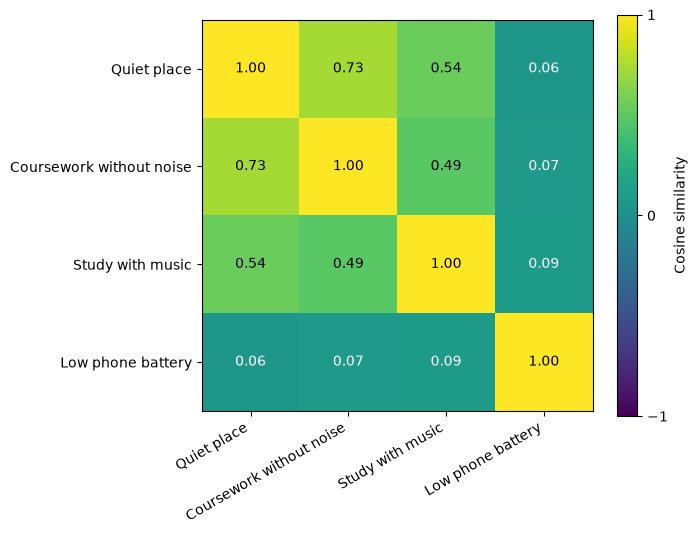

In [ ]:
#| eval: false
#| code-fold: true
#| code-summary: "Show heat-map code"
#| fig-cap: "Cosine similarity between campus-themed sentences. Short axis labels follow the sentence order above."
#| fig-alt: "A four-by-four annotated heat map. The two requests for quiet have similarity 0.73, their similarities to studying with music are 0.54 and 0.49, and similarities to the phone-battery sentence are close to zero. Each diagonal entry is 1."
import matplotlib.pyplot as plt

similarities = cosine_similarity(sentence_embeddings)
labels = ["Quiet place", "Coursework without noise", "Study with music", "Low phone battery"]
fig, ax = plt.subplots(figsize=(7, 5.5))
image = ax.imshow(similarities, cmap="viridis", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
ax.set_yticks(range(len(labels)), labels)
for row in range(len(labels)):
    for col in range(len(labels)):
        ax.text(
            col, row, f"{similarities[row, col]:.2f}",
            ha="center", va="center",
            color="black" if similarities[row, col] > 0.4 else "white",
        )
fig.colorbar(image, ax=ax, label="Cosine similarity", ticks=[-1, 0, 1])
fig.tight_layout()
plt.show()


Each row of `sentence_embeddings` represents one sentence; the 384 columns are learned features. Unlike our sparse representations, the columns no longer correspond to vocabulary terms. The first few coordinates show what an embedding looks like, but individual coordinates do not have simple labels such as ''contains battery.'' Interpret relationships through the vectors as a whole.

The heat map compares every pair of sentences. Brighter cells indicate higher cosine similarity; the numbers give the exact scores rounded to two decimal places. The short axis labels follow the order of the sentences above. Each sentence has similarity 1 with itself. Compare the two requests for quiet with the preference for background music and the sentence about a phone battery. These scores reflect the model's learned associations, not a guarantee that two sentences express the same need.

We requested `normalize_embeddings=True`, which rescales each vector to length 1 without changing its direction. For these vectors, a dot product gives the same score as cosine similarity; we use `cosine_similarity` to make the comparison explicit.

You used sentence embeddings in homework 6 to cluster recipe titles. For retrieval, we will instead encode a query and compare its vector with catalog-description vectors. **The representation can be reused; what we do with it changes.**

::: {.callout-tip collapse="true" title="Discussion: sentence-similarity prediction"}

The first two sentences express a similar need using different words: a quiet place for academic work. The third also concerns studying and sound, but expresses a different preference. A model can recognize this shared topic without fully capturing the distinction between wanting quiet and wanting music. The battery sentence concerns a different need.

In the saved output, the first two sentences have similarity about 0.73. Their similarities to the background-music sentence are lower (about 0.54 and 0.49), and their similarities to the battery sentence are close to zero. Even when two sentences have a relatively high similarity, check whether their differences matter for the task. Recommending a way to block sound to someone who wants background music could miss what they are asking for.

:::


## Information retrieval

**Information retrieval** (IR) is the task of finding useful items in a collection in response to a query. Unlike a classifier, which predicts a label, a retrieval system returns a ranked list. Several results may be useful, and relevance depends partly on what the user intends.

![The main components of an information-retrieval system. Documents are processed and indexed ahead of time; a query is processed at search time and compared with the index to produce a ranked list.](img/IR.jpeg){#fig-information-retrieval-pipeline fig-alt="Documents pass through document processing into a document index. A query passes through query processing into a query vector. A search component compares them using dense, keyword, or hybrid search and returns a ranked list of documents." fig-align="center" width="100%"}

Consider these queries for our campus-survival catalog:

- *Every outlet is occupied and my phone is at 2%.*
- *I want to study without hearing the conversation at the next table.*
- *My wrists get sore after a full day of coding.*
- *20,000 mAh battery*
- *HUB-7X*
- *HUB-7Y*

Which queries require understanding related meanings? Which contain specifications or identifiers that should match exactly? A useful search system often needs both abilities.

How can we use the representations we have learned to find useful catalog entries? We first represent the shopper's query as a vector, using the same method we used for the catalog descriptions. We then compare the query vector with each description vector using cosine similarity and return the entries with the highest scores.

We will try this with two representations. Comparing sparse TF–IDF vectors gives us **sparse retrieval**, which emphasizes matching terms. Comparing dense text embeddings gives us **dense retrieval**, which can connect texts with different wording but related meanings. We will inspect the results to see when each approach helps and where it falls short.

### Sparse retrieval with TF–IDF

We already fitted the TF–IDF vectorizer on the catalog descriptions. At query time, we transform a new query using the same fitted vocabulary, compare it with every document vector, and rank the entries by cosine similarity.

First consider a query containing an exact product identifier.

In [11]:
def sparse_retrieve(query, k=3):
    query_tfidf = tfidf.transform([query])
    scores = cosine_similarity(query_tfidf, product_tfidf).ravel()
    top_indices = np.argsort(scores)[::-1][:k]
    results = products.iloc[top_indices].copy()
    results["score"] = scores[top_indices]
    return results[["product_id", "title", "score", "text"]]


sparse_retrieve("HUB-7X", k=3)

,product_id,title,score,text
6,C007,USB-C hub,0.359633,"The HUB-7X adds HDMI, Ethernet, an SD-card reader, and three USB ports to laptops with limited connections."
13,C014,Vancouver weather guide,0.000000,An article about preparing for wet and dark winter commutes in Vancouver.
12,C013,Study-skills article,0.000000,An article describing ways to concentrate in a busy library.


The identifier `HUB-7X` points to the USB-C hub. Inspecting `tfidf.build_analyzer()("HUB-7X")` would show the tokens `hub` and `7x`: the vectorizer matches terms rather than checking an entire identifier as one unit. When a model number must match exactly, check that constraint explicitly.

The remaining results have score zero. They are returned because we asked for three results, not because the retriever found three useful matches. Their order is just a tie. Now consider a need expressed using words that do not occur in the relevant product description.

In [12]:
semantic_query = "How can I avoid hearing people talk while I study?"
sparse_retrieve(semantic_query, k=4)

,product_id,title,score,text
8,C009,Pomodoro timer,0.269859,Distraction-free timer with 25- and 50-minute study modes. It does not connect to a phone.
13,C014,Vancouver weather guide,0.000000,An article about preparing for wet and dark winter commutes in Vancouver.
12,C013,Study-skills article,0.000000,An article describing ways to concentrate in a busy library.
11,C012,White-noise machine,0.000000,"Produces fan, rain, and ambient sounds without playing music. Intended for sleep or concentration."


The headphones are designed for this situation, but the query never says *headphones*, *noise*, or *cancellation*. TF–IDF instead emphasizes the exact word *study* and misses the relationship between *avoid hearing people talk* and noise cancellation. A nonzero score indicates shared vocabulary, not necessarily relevance.

### Dense retrieval with a pretrained embedding model

We now use the same sentence-embedding model to encode every catalog description. Dense retrieval embeds the query into the same vector space and compares it with those document vectors, allowing differently worded texts to receive similar vectors. We reuse the pretrained model rather than training one on our tiny catalog.


In [13]:
#| eval: false
product_embeddings = embedding_model.encode(
    products["text"].tolist(), normalize_embeddings=True
)
product_embeddings.shape


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(14, 384)

The model produces one 384-dimensional dense vector for each catalog entry. Because we requested normalized vectors, their dot products are equal to their cosine similarities.

In [14]:
#| eval: false
def dense_retrieve(query, k=3):
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = cosine_similarity(query_embedding, product_embeddings).ravel()
    top_indices = np.argsort(scores)[::-1][:k]
    results = products.iloc[top_indices].copy()
    results["score"] = scores[top_indices]
    return results[["product_id", "title", "score", "text"]]


dense_retrieve(semantic_query, k=4)

,product_id,title,score,text
0,C001,Sony WH-1000XM6 headphones,0.321432,Over-ear wireless headphones with active noise cancellation and up to 30 hours of battery life. Useful for studying ...
12,C013,Study-skills article,0.320502,An article describing ways to concentrate in a busy library.
8,C009,Pomodoro timer,0.293729,Distraction-free timer with 25- and 50-minute study modes. It does not connect to a phone.
3,C004,Sunrise alarm clock,0.205969,Gradually brightens the room before the alarm sounds. Designed to make waking up on dark winter mornings easier.


Compare this ranking with the TF–IDF results. Dense retrieval ranks the noise-cancelling headphones first by connecting *avoid hearing people talk* with active noise cancellation, even though the wording differs. The study-skills article scores almost as highly. It is related to studying, but it does not provide the same way of reducing nearby conversation. Whether it counts as useful depends on the search task. An embedding model estimates textual similarity rather than knowing the user's intent with certainty.

Both methods return a ranked list. What differs is how they compare the query with each document: sparse retrieval compares weighted terms, while dense retrieval compares learned text embeddings. Neither score guarantees that a result will be useful.

For this small catalog, we compare the query with every document. Larger systems use indexes to find candidates efficiently, but the goal is the same: return documents likely to help with the query.

Neither method is always preferable. Exact terms can favour sparse retrieval; paraphrases can favour dense retrieval. **Hybrid retrieval** combines results from both approaches. We will not implement it here, but it is a useful option to know about when a system needs both kinds of matching.


### Evaluating retrieval

A few appealing search results are not enough to establish that a retriever works. Start with several realistic queries and identify which documents would help answer each one. Then inspect the top results: did they include the evidence you needed? Did irrelevant results crowd it out? Include exact terms, paraphrases, and questions the collection cannot answer.

Use these observations to improve the system, then check it on held-out queries rather than repeatedly tuning to the same examples. This is the same reason we protected test data when comparing classifiers.

::: {.callout-note collapse="true" title="Optional: retrieval evaluation keywords"}
For more systematic evaluation, useful search terms include **precision@$k$**, **recall@$k$**, **mean reciprocal rank (MRR)**, and **normalized discounted cumulative gain (NDCG)**. They capture different aspects of retrieval quality. We will not develop these metrics here.
:::


### Exercise 18.1: Compare retrieval methods

Before running the retrievers, predict which method is likely to work better for each query. Then run both methods and explain their rankings.

1. `HUB-7X`
2. `I keep checking social media whenever I use my phone as a study timer.`
3. `Getting out of bed for an 8 a.m. class is impossible in December.`
4. `HUB-7Y`

Identify where exact word overlap helps, where a paraphrase creates vocabulary mismatch, and how each system behaves when the requested model number is absent from the catalog.

For each query, decide which catalog entries would actually be useful. Did each method place those entries in its top three? Explain one irrelevant result rather than treating a high score as proof of relevance.

::: {.callout-tip collapse="true" title="Discussion"}

Treat these as expectations to check against your results, rather than required rankings.

1. **`HUB-7X`:** Sparse retrieval has a useful exact-term match to the USB-C hub description. Dense retrieval may also find it, but semantic similarity alone does not enforce an exact model number.
2. **Phone distractions:** The Pomodoro timer is a useful candidate because it works without connecting to a phone. Dense retrieval may connect the situation to this description; sparse retrieval also has helpful overlap in words such as *phone* and *timer*. This is not a case where dense retrieval must win.
3. **December mornings:** The sunrise alarm clock is a useful candidate. Dense retrieval may connect difficulty getting up in December with waking on dark winter mornings, despite the different wording.
4. **`HUB-7Y`:** Neither method can retrieve a description of this exact model because it is absent. Both may return HUB-7X as a related candidate. That result does not establish that HUB-7Y is available.

Check whether these useful candidates appear in the top three. For an irrelevant result, look for shared words or broad semantic associations that explain its score without meeting the user's need. Rankings may vary; the important part is your explanation using the returned descriptions.

:::


## Language models and LLMs

::: {.callout-tip title="Activity: Become a language model"}
For each context, suggest several possible next words and assign rough probabilities. Your probabilities for each row should add to 1.

| Context | Possible next words and probabilities |
|---|---|
| *Too much ...* | |
| *Peanut butter and ...* | |
| *The capital of Canada is ...* | |
| *I sat on the bank of the ...* | |

Where did you assign high probability to one word? Where were several continuations plausible?
:::

### What did you just do?

You acted like a **language model**: you used the preceding context to assign probabilities to possible continuations. A language model does this with **tokens**, which may be complete words, parts of words, punctuation, or other units. We can summarize its task as

$$
P(\text{next token} \mid \text{context}).
$$

There is not always one correct next token. A model estimates a distribution and uses it to choose a continuation. For example, after *Peanut butter and*, the model might choose *jelly*. It then predicts another token using *Peanut butter and jelly* as the context. Repeating this process one token at a time produces text. A plausible continuation can still contain an incorrect claim: predicting likely text is not the same as checking its truth. Models that predict plausible sequences can also support applications such as transcription, translation, and summarization.

The basic idea predates modern neural networks. In 1948, Claude Shannon described language probabilistically and constructed increasingly realistic approximations to English. He later studied how well people could predict upcoming characters. Modern language models pursue the same broad idea at a vastly larger scale: learn regularities in language by predicting what comes next.

### From language models to LLMs

A **large language model (LLM)** is a language model implemented with a large neural network and trained on a large collection of data. During **pretraining**, it learns to predict tokens from text. Many models then undergo **post-training**, including methods such as instruction tuning and preference-based training, to make their responses more useful. Reinforcement learning from human feedback (RLHF) is one possible post-training method; not every LLM uses the same recipe.

Instruction tuning uses examples of instructions and responses to help the model continue a prompt in the form of a useful answer. This helps connect next-token prediction to the assistants we interact with, but does not guarantee that their answers are correct.

The embedding model we used earlier returns a numerical vector for comparing texts. A generative language model instead produces new text, such as an answer to a question.

For our purposes, we can use an LLM without studying its internal neural-network architecture. We provide a **prompt**—the input text containing our instructions and any relevant information—and the model generates a response:

```python
generated_text = language_model(prompt)
```

### Clear instructions and supplied evidence

Compare these prompts:

> **Prompt A:** Recommend gear for my commute.

> **Prompt B:** I cycle home after evening labs in Vancouver rain and carry a laptop. Recommend exactly two products and explain briefly how each addresses my needs.

If you have access to an LLM, try both. Which prompt produces a more relevant and appropriately formatted response? Does either response make unsupported assumptions? Prompt B communicates the situation, constraints, and requested output more clearly, so it will often elicit a better response.

The model's **weights remain unchanged** when we improve a prompt. We are not training it; we are eliciting different behaviour from the same model. Rephrasing a question cannot reliably supply facts that the model lacks, such as the current contents of a private product catalog. A model's parameters are not a dependable database, and its answers can be outdated or unsupported.

We can, however, supply new evidence in the prompt. The model can use that evidence without changing its weights. Its **context window** limits how many tokens it can process at once. Inserting an entire document collection may exceed that limit, and irrelevant text can be distracting. Instead, we can retrieve a small amount of relevant evidence and add it to the prompt before generation. This motivates **retrieval-augmented generation**.

## Retrieval-augmented generation

**Retrieval-augmented generation (RAG)** combines an information-retrieval system with a generative language model:

1. **Retrieve:** find text chunks relevant to the user's query.
2. **Augment:** place those chunks, the query, and instructions in a prompt.
3. **Generate:** ask a language model to answer from the supplied context.

![A RAG pipeline retrieves catalog documents relevant to a rainy evening bicycle commute and supplies them to an LLM, which recommends a waterproof laptop backpack and bike-light set.](img/RAG-bike-ex.png){#fig-rag-bike-example fig-alt="A user asks which two products would help with a rainy bicycle commute after an evening lab while carrying a laptop. A retriever selects relevant documents from an indexed corpus. The documents and query enter a prompt, and an LLM generates the recommendations waterproof laptop backpack and bike-light set." fig-align="center" width="100%"}

RAG lets an application use material that was not part of the language model's training data. It can make answers easier to update and support with sources. It does not guarantee correctness: the retriever can miss necessary evidence, and the generator can ignore or misrepresent retrieved evidence.

Read the following example as a guided tour of a working system. At each stage, inspect the output and explain its role in producing the final answer. You can follow the walkthrough using the displayed outputs without running the models yourself. Keep asking three questions: **What evidence did we retrieve? What did we put in the prompt? Is the answer supported?** These questions will help us inspect the system one stage at a time.


### Step 1: Split documents into chunks

Long documents are commonly divided into smaller **chunks** before they are embedded. Small chunks can isolate a precise passage, but they may omit context needed to interpret it. Large chunks retain more context, but they may mix several topics and consume more of the model's context window. Overlap can preserve text near a boundary at the cost of storing repeated content.

Each catalog description is already a short, natural chunk, so the function below leaves these entries intact. The same code would split longer descriptions. Production systems often use token-aware or structure-aware splitting so headings, sentences, and paragraphs are not broken arbitrarily.

For example, imagine a longer description contains: *''The hub supports two monitors. This requires a laptop with Thunderbolt support.''* A boundary between those sentences could leave a retrieved chunk with the claim but without its qualification. Keeping the sentences together, or including overlap, could preserve the evidence needed to answer ''Will it support two monitors on my laptop?'' The goal is to retrieve enough context to interpret a claim, not merely a matching phrase.


In [15]:
def split_into_chunks(text, chunk_size=50, overlap=10):
    if overlap >= chunk_size:
        raise ValueError("overlap must be smaller than chunk_size")

    words = text.split()
    step = chunk_size - overlap
    return [" ".join(words[start : start + chunk_size])
            for start in range(0, len(words), step)]


chunk_records = []
for product in products.itertuples(index=False):
    for chunk_number, chunk_text in enumerate(split_into_chunks(product.text)):
        chunk_records.append(
            {
                "chunk_id": f"{product.product_id}-{chunk_number}",
                "product_id": product.product_id,
                "title": product.title,
                "item_type": product.item_type,
                "text": chunk_text,
            }
        )

chunks = pd.DataFrame(chunk_records)
chunks

,chunk_id,product_id,title,item_type,text
0,C001-0,C001,Sony WH-1000XM6 headphones,product,Over-ear wireless headphones with active noise cancellation and up to 30 hours of battery life. Useful for studying ...
1,C002-0,C002,Pocket power bank,product,"Portable 20,000 mAh battery with two USB-C ports. Recharges mobile devices several times when wall power is unavaila..."
2,C003-0,C003,Waterproof laptop backpack,product,Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and not...
3,C004-0,C004,Sunrise alarm clock,product,Gradually brightens the room before the alarm sounds. Designed to make waking up on dark winter mornings easier.
4,C005-0,C005,Ergonomic keyboard,product,Split keyboard with a padded wrist rest. Designed to reduce wrist strain during long typing and programming sessions.
5,C006-0,C006,Laptop stand,product,Raises a laptop screen to eye level and folds flat for carrying. An external keyboard is recommended for prolonged use.
6,C007-0,C007,USB-C hub,product,"The HUB-7X adds HDMI, Ethernet, an SD-card reader, and three USB ports to laptops with limited connections."
7,C008-0,C008,Insulated travel mug,product,Leak-resistant 500 mL mug that keeps coffee hot for eight hours. Fits standard campus cup holders.
8,C009-0,C009,Pomodoro timer,product,Distraction-free timer with 25- and 50-minute study modes. It does not connect to a phone.
9,C010-0,C010,Bike-light set,product,Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after...


### Step 2: Embed and store the chunks

We embed chunks because these are the units the retriever will return. The DataFrame acts as our small document store, and the NumPy array acts as our vector store.

Our query explicitly asks for products, so we use the `item_type` metadata to exclude articles before ranking. Metadata filters are useful when a query contains constraints that should be enforced exactly rather than approximated through semantic similarity.

In [16]:
#| eval: false
chunk_embeddings = embedding_model.encode(
    chunks["text"].tolist(), normalize_embeddings=True
)


def retrieve_chunks(query, k=3, item_type=None):
    query_embedding = embedding_model.encode([query], normalize_embeddings=True)
    scores = cosine_similarity(query_embedding, chunk_embeddings).ravel()

    candidate_indices = chunks.index
    if item_type is not None:
        candidate_indices = chunks.index[chunks["item_type"] == item_type]

    candidate_scores = scores[candidate_indices]
    top_indices = candidate_indices[np.argsort(candidate_scores)[::-1][:k]]
    results = chunks.loc[top_indices].copy()
    results["score"] = scores[top_indices]
    return results[
        ["chunk_id", "product_id", "title", "item_type", "score", "text"]
    ]


rag_query = (
    "I commute by bike after evening labs in Vancouver rain and carry a laptop. "
    "Which two products should I consider, and why?"
)
retrieve_chunks(rag_query, k=2, item_type="product")

,chunk_id,product_id,title,item_type,score,text
2,C003-0,C003,Waterproof laptop backpack,product,0.561849,Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and not...
9,C010-0,C010,Bike-light set,product,0.414160,Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after...


### Step 3: Construct an augmented prompt

The prompt tells the model how to use the retrieved text. In applications where unsupported answers are costly, it is useful to instruct the model to say when the context is insufficient. We also attach source identifiers so that the answer can point back to evidence.

Our prompt is deliberately specific to the catalog task: recommend two products. If you adapt the pipeline to answer policy questions or summarize recipes, change these instructions to match the new task.


In [17]:
#| eval: false
def build_rag_prompt(query, retrieved_chunks):
    context_blocks = []
    for row in retrieved_chunks.itertuples(index=False):
        context_blocks.append(
            f"SOURCE ID: {row.chunk_id}\n"
            f"PRODUCT TITLE: {row.title}\n"
            f"DESCRIPTION: {row.text}"
        )
    context = "\n\n".join(context_blocks)

    return f"""Answer the question using only the context below.
If the context does not contain enough information, say that you do not know.
Recommend exactly two products. Use their exact titles, explain briefly why each
fits the user's needs, and cite each supporting source ID in square brackets.

CONTEXT
{context}

QUESTION
{query}

ANSWER
"""


rag_chunks = retrieve_chunks(rag_query, k=2, item_type="product")
print(build_rag_prompt(rag_query, rag_chunks))

Answer the question using only the context below.
If the context does not contain enough information, say that you do not know.
Recommend exactly two products. Use their exact titles, explain briefly why each
fits the user's needs, and cite each supporting source ID in square brackets.

CONTEXT
SOURCE ID: C003-0
PRODUCT TITLE: Waterproof laptop backpack
DESCRIPTION: Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and notes dry during wet commutes.

SOURCE ID: C010-0
PRODUCT TITLE: Bike-light set
DESCRIPTION: Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after dark.

QUESTION
I commute by bike after evening labs in Vancouver rain and carry a laptop. Which two products should I consider, and why?

ANSWER



Inspecting the prompt is an important debugging step. The language model cannot use evidence that the retriever failed to include. Notice also that the retrieved text is untrusted input. A document could contain instructions such as ''ignore the user's question.'' Robust applications must distinguish application instructions from document content and defend against this form of **prompt injection**.

### Step 4: Generate an answer

Retrieval and generation are separate parts of the pipeline. The same retrieved chunks and prompt can be sent to a small local model, a larger local model, or a hosted LLM. Here we use `google/flan-t5-small` so that the example can run on an ordinary computer. It is not an LLM by contemporary standards, and its output quality should not be taken as a limit of RAG.

The saved output is shown in the rendered book, but the cell is not executed during the build. Running it locally downloads the model. Output can vary across library and model versions.

In [18]:
#| eval: false
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

generator_name = "google/flan-t5-small"
generator_tokenizer = AutoTokenizer.from_pretrained(generator_name)
generator_model = AutoModelForSeq2SeqLM.from_pretrained(generator_name)


def generate_text(prompt, max_new_tokens=100):
    model_inputs = generator_tokenizer(prompt, return_tensors="pt", truncation=True)
    output_ids = generator_model.generate(
        **model_inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
    )
    return generator_tokenizer.decode(output_ids[0], skip_special_tokens=True)


def answer_with_rag(query, k=3, item_type=None):
    retrieved = retrieve_chunks(query, k=k, item_type=item_type)
    prompt = build_rag_prompt(query, retrieved)
    answer = generate_text(prompt)
    return {
        "answer": answer,
        "sources": retrieved[["chunk_id", "title", "score", "text"]],
        "prompt": prompt,
    }


rag_result = answer_with_rag(rag_query, k=2, item_type="product")
print(rag_result["answer"])
display(rag_result["sources"])

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Bike-light set and waterproof laptop backpack


,chunk_id,title,score,text
2,C003-0,Waterproof laptop backpack,0.561849,Rain-resistant backpack with sealed zippers and a padded compartment for a 16-inch laptop. Keeps electronics and not...
9,C010-0,Bike-light set,0.414160,Rechargeable front and rear bicycle lights with weather-resistant housings. Improves visibility when commuting after...


The retrieved sources make it possible to check the generated response. With this small generator, the wording may be incomplete and it may fail to follow the requested citation format even when retrieval succeeds. A fully supported response would say something like:

- **Waterproof laptop backpack** protects the laptop and notes from rain during a wet commute [C003-0].
- **Bike-light set** improves the cyclist's visibility after an evening lab and has weather-resistant housings [C010-0].

This comparison is part of RAG evaluation, not merely a cosmetic rewrite. The evidence was retrieved correctly, so omitting a product, reason, or citation would be a **generation failure**. Returning the retrieved sources alongside the answer helps us identify that distinction, although a source list alone does not prove that every generated claim is supported.

Check the saved answer against three concrete requirements:

| Requirement | What the answer does |
|---|---|
| Name two relevant products | Names the bike-light set and backpack; both are supported by the retrieved descriptions. |
| Explain how each helps | Gives no explanation. |
| Cite supporting source IDs | Gives no citations. |

The answer is partly useful, but incomplete. Keeping this distinction visible is more informative than calling the whole pipeline either successful or unsuccessful.


#### Optional: replace the generator with Qwen

The weak answer above is a useful reminder that a RAG pipeline is not tied to one language model. We can keep the catalog, embeddings, retriever, and prompt exactly as they are and replace only the generator. A more capable instruction-tuned chat model will often follow constraints such as "exactly two products" and source citations better, although no model guarantees a correct or fully supported answer.

The optional cell below uses `Qwen/Qwen2.5-1.5B-Instruct`. It is not executed when the book is rendered because it requires a substantially larger download and more memory than FLAN-T5-small. Students with suitable hardware can run it themselves—or pass `rag_result["prompt"]` to another local or hosted instruction-following LLM. The retrieval part of the pipeline does not need to change.

In [19]:
#| eval: false
from transformers import AutoModelForCausalLM, AutoTokenizer

qwen_name = "Qwen/Qwen2.5-1.5B-Instruct"
qwen_tokenizer = AutoTokenizer.from_pretrained(qwen_name)
qwen_model = AutoModelForCausalLM.from_pretrained(
    qwen_name, torch_dtype="auto"
)

messages = [
    {
        "role": "system",
        "content": "Follow the user's instructions and use only the supplied context.",
    },
    {"role": "user", "content": rag_result["prompt"]},
]

model_inputs = qwen_tokenizer.apply_chat_template(
    messages,
    add_generation_prompt=True,
    tokenize=True,
    return_dict=True,
    return_tensors="pt",
).to(qwen_model.device)

output_ids = qwen_model.generate(
    **model_inputs, max_new_tokens=160, do_sample=False
)
new_token_ids = output_ids[0, model_inputs["input_ids"].shape[1] :]
qwen_answer = qwen_tokenizer.decode(new_token_ids, skip_special_tokens=True)
print(qwen_answer)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

To address your need to commute by bike after evening labs in Vancouver rain while carrying a laptop, I recommend considering the following two products:

1. **Bike-Light Set [C010-0]** - This product is essential because it provides both front and rear bicycle lights, which are crucial for improved visibility especially at night or during rainy conditions. The rechargeable nature of these lights ensures they can be used continuously without needing frequent recharging, making them convenient for long commutes. Additionally, the weather-resistant housing protects the lights from moisture, ensuring they remain functional even if exposed to rain.

2. **Waterproof Laptop Backpack [C003-0]** - While this product primarily addresses keeping electronic devices dry during rainy commutes, its inclusion here is important as it complements


A stronger generator may produce a more complete response, but we should evaluate it against the same evidence. The saved Qwen response illustrates why:

| Generated claim or behaviour | Evidence check |
|---|---|
| The bike lights improve visibility | Supported by the catalog description. |
| Rechargeability means continuous use without frequent recharging | Unsupported: the description gives no battery runtime. |
| The backpack explanation ends partway through | Incomplete: check whether the generation limit was reached. |

A source ID beside a sentence does not prove that its source supports every claim. Increasing the output limit could allow the response to finish, but would not by itself fix unsupported claims. Use the same evidence checks whichever generator you choose.


### The complete pipeline

Our implementation contains two phases.

During **indexing**, we:

1. load documents;
2. split them into chunks;
3. embed the chunks; and
4. store the text, metadata, and vectors.

For each query, we:

1. embed the query;
2. retrieve the top-\(k\) chunks;
3. construct a prompt containing those chunks;
4. generate an answer; and
5. return the answer with its sources.

Indexing is normally done only when documents are added or changed. Query processing happens for every user request.

We implemented the pipeline directly to make each step visible.

::: {.callout-note collapse="true" title="Optional: explore RAG with LangChain"}

If you would like to build on this example, explore [LangChain's retrieval guide](https://docs.langchain.com/oss/python/deepagents/retrieval). LangChain provides reusable components for loading documents, splitting text, embedding chunks, retrieving passages, and connecting to language models.

Start with the guide's **2-step RAG** approach: retrieve relevant passages, then supply them to a model to generate an answer. This follows the same sequence we implemented here. As you explore, identify where the framework performs each familiar step, and keep inspecting the retrieved evidence, prompt, and answer. You do not need LangChain to complete this chapter.

:::


### Evaluating and improving a RAG pipeline

A final answer can fail for different reasons:

- **Retrieval failure:** the necessary evidence was not among the retrieved chunks.
- **Context failure:** a chunk contained relevant words but omitted information needed to interpret them.
- **Generation failure:** the evidence was present, but the model ignored, distorted, or contradicted it.
- **Knowledge-base failure:** the required information was absent, incorrect, or outdated in the source documents.

These failures call for different fixes. Changing the prompt will not recover a document that was never retrieved. Changing the embedding model will not correct an inaccurate source document. Evaluate intermediate outputs instead of treating the system as one black box.

Evaluation should cover both retrieval and the generated answer—for example, whether the answer addresses the question and whether its claims are supported by the retrieved context. For this chapter, inspecting a small set of queries, retrieved passages, and answers is enough to practise this distinction.

::: {.callout-note collapse="true" title="Optional: further evaluation tools"}
Frameworks such as Ragas provide automated metrics for retrieval and generated answers. These can help when evaluating many queries, but their scores should complement inspection and human evaluation.
:::

#### Important design choices

Several choices affect both quality and cost:

- **Embedding model:** It should suit the language and domain of the documents.
- **Chunking:** Chunk size, overlap, and document structure determine what can be retrieved together.
- **Retrieval method:** Sparse, dense, and hybrid methods have different strengths.
- **Number of chunks:** Increasing \(k\) may recover more evidence, but it also adds irrelevant context and consumes space.
- **Prompt:** The instructions should specify the task, permitted evidence, desired output, and behaviour when evidence is missing.
- **Generator:** Models differ in instruction-following ability, context size, latency, cost, and deployment constraints.

Changing any of these components should be followed by evaluation on representative queries.

#### Risks and limitations

RAG provides access to external information; it does not make the overall system inherently trustworthy.

- Retrieved documents can contain private, copyrighted, biased, malicious, or outdated information.
- Embedding models may perform unevenly across languages and social groups.
- A generated answer can make claims that are absent from—or contradicted by—the retrieved evidence.
- Document text can attempt to manipulate the generator through prompt injection.
- Logging queries and retrieved passages may expose sensitive information.
- Model calls and large context windows introduce latency, monetary cost, and environmental cost.

The appropriate safeguards depend on the application. High-stakes systems may require access controls, document provenance, citations, abstention, human review, and monitoring after deployment.

#### Exercise 18.2: Diagnose a failed answer

A shopper asks, ''Do you sell a HUB-7Y?'' That exact model is absent from the catalog, but the retriever returns the similar `HUB-7X`. The generator answers, ''Yes, the HUB-7Y is available.''

1. Does the retrieved passage support the answer?
2. Is the main failure in retrieval, generation, or the knowledge base?
3. What should a better answer say? Distinguish ''not listed in this catalog'' from ''the store does not sell it.''

Explain your reasoning using the retrieved description rather than the model's confidence or writing style.

::: {.callout-tip collapse="true" title="Discussion"}

1. No. The retrieved passage describes HUB-7X, not HUB-7Y. Similar identifiers are not interchangeable.
2. The unsupported assertion is a **generation failure**: the model claims availability without evidence. Returning a related item is not necessarily a retrieval failure when no exact match exists. The catalog also has an information gap for this question, but absence alone does not tell us whether the catalog is incomplete or the store does not sell the item.
3. A supported answer would be: ''I cannot confirm whether HUB-7Y is available from this catalog. It lists HUB-7X, a different model.''

The existing prompt asks for exactly two recommendations. For an availability question, revise that instruction so the generator can answer the question directly and acknowledge missing evidence.

:::


#### Optional coding exploration: Adapt the pipeline

If you would like to experiment with the implementation, try this extension. It goes beyond the chapter's learning expectations.

Add two short documents to the knowledge base and write three realistic questions about them. At least one question should use different wording from its relevant document.

Update the prompt instructions if your new questions are not asking for two product recommendations. Then:

1. rebuild the chunk embeddings;
2. inspect the top-three chunks for each query;
3. record whether the relevant chunk was retrieved;
4. generate an answer only after checking retrieval; and
5. identify one change that improves the pipeline and one trade-off introduced by that change.

::: {.callout-tip collapse="true" title="Discussion"}

There is no single correct set of documents or rankings. A useful investigation should make the following visible:

- Which document or passage should help answer each question, including the paraphrased question.
- Whether that passage appears in the top three results, before judging generation.
- Which generated claims are supported by the retrieved passages, and whether the answer follows your revised task instructions.
- One comparison before and after a change, with a reason for the outcome and a trade-off.

For example, increasing the number of retrieved chunks may recover missing evidence while adding irrelevant context. It is also useful to report a change that did not help: explain what you observed rather than assuming that a more complicated pipeline must be better.

:::


## Summary

- NLP systems need numerical representations of text; the chosen representation determines what kinds of similarity they can detect.
- Bag-of-words and TF–IDF are sparse and effective for exact vocabulary matches, but they do not directly represent meaning or word order.
- Word and text embeddings encode some semantic relationships in dense vectors, but their similarities are imperfect and can reproduce social biases.
- Retrieval produces a ranking, not a guarantee: sparse retrieval is strong on exact terms, while dense retrieval can connect differently worded ideas.
- A language model predicts a distribution over the next token. Scaling and post-training produce more capable LLMs, but fluent answers can still be incorrect. Clearer instructions do not change model weights; supplied evidence adds information the model can use in its context.
- RAG means **retrieve, augment, generate**: retrieve relevant chunks, add them to the prompt, and ask a language model to answer from that context.
- Inspect the evidence and intermediate steps. Retrieval, context, generation, and the knowledge base can each fail, and fluent output is not proof of a supported answer.